In [3]:
from scipy.stats import norm  # For normal distribution CDF (phi function)
import math
import numpy as np

In [3]:
phi_z = 0.6125
abs(norm.ppf(phi_z))

np.float64(0.2858408748811657)

In [7]:
def log2_map_from_tanh(norm_value, min_val, max_val):
    norm_01 = (norm_value + 1.0) / 2.0
    log_min = math.log2(min_val)
    log_max = math.log2(max_val)
    log_val = log_min + norm_01 * (log_max - log_min)
    return 2 ** log_val

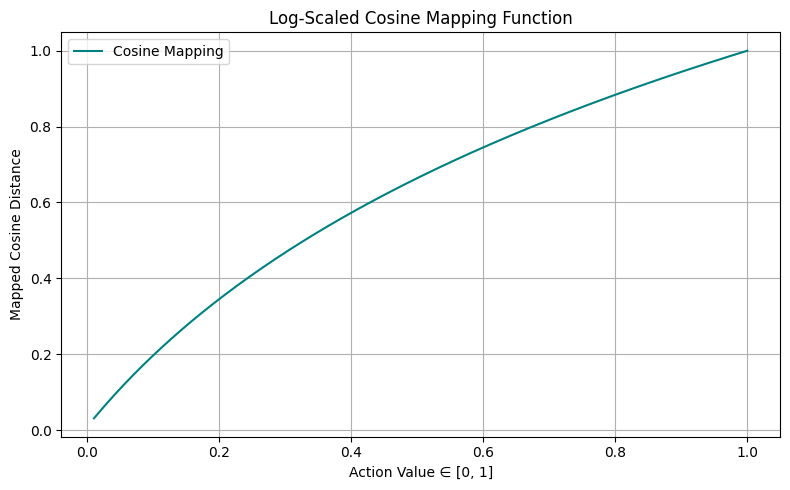

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def cosine_mapping_from_0_to_1(action_val, max_val=1.0, log_base=4.0, start_at=0.01):
    """
    Maps action ∈ [0, 1] to cosine distance ∈ [start_at, max_val]
    - action = 0 → start_at (very small constraint)
    - action = 1 → max_val
    - log-scaled growth
    """
    action = float(torch.clamp(torch.tensor(action_val), 0.0, 1.0))
    scaled = np.log1p(action * (log_base - 1)) / np.log(log_base)  # ∈ [0, 1]
    return start_at + (max_val - start_at) * scaled

# Generate input values in [0, 1]
x_vals = np.linspace(0.01, 1, 200)
y_vals = [cosine_mapping_from_0_to_1(x) for x in x_vals]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label='Cosine Mapping', color='teal')
plt.xlabel("Action Value ∈ [0, 1]")
plt.ylabel("Mapped Cosine Distance")
plt.title("Log-Scaled Cosine Mapping Function")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [3]:
N=9
action_space = [ 
    [x, y] for x in np.linspace(-1, 1, N) for y in np.linspace(-1, 1, N)
]

In [6]:
np.linspace(-1, 1, 9)

array([-1.  , -0.75, -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ])

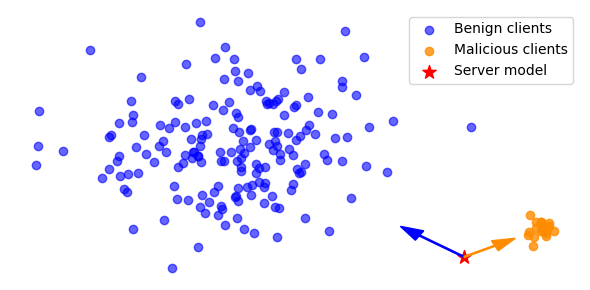

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Define a function to draw arrow with border
def draw_arrow(ax, start, direction, color, label=None):
    arrow = FancyArrowPatch(
        posA=start,
        posB=start + direction,
        arrowstyle='->',
        mutation_scale=15,
        linewidth=1.5,
        edgecolor='black',  # Black border
        facecolor=color,    # Fill color
    )
    ax.add_patch(arrow)


# Set random seed for reproducibility
np.random.seed(40)

# Server model (theta^t)
server = np.array([0, 0])

# Generate benign clients (scattered, loose cluster)
benign_center = np.array([-3, 2])  # Place it far from server
benign_clients = benign_center + np.random.randn(180, 2) * 0.9  # Loose cluster

# Generate malicious clients (tight cluster)
malicious_center = np.array([1, 0.5])  # Closer to server
malicious_clients = malicious_center + np.random.randn(20, 2) * 0.1  # Tight cluster

# Compute average direction vectors
benign_direction = np.mean(benign_clients - server, axis=0)
malicious_direction = np.mean(malicious_clients - server, axis=0)

# Normalize for arrow plotting
benign_dir_unit = benign_direction / np.linalg.norm(benign_direction)
malicious_dir_unit = malicious_direction / np.linalg.norm(malicious_direction) * 0.75

# Plotting
plt.figure(figsize=(6, 3))

# Plot benign and malicious clients
plt.scatter(*benign_clients.T, color='blue', alpha=0.6, label='Benign clients')
plt.scatter(*malicious_clients.T, color='darkorange', alpha=0.8, label='Malicious clients')

# Plot server model
plt.scatter(*server, color='red', s=100, marker='*', label=r'Server model')
# plt.text(server[0] + 0.2, server[1] + 0.2, r'$\theta^t$', fontsize=14, color='red')

# Draw direction arrows
plt.arrow(*server, *benign_dir_unit, color='blue', width=0.02, head_width=0.2, length_includes_head=True)
plt.arrow(*server, *malicious_dir_unit, color='darkorange', width=0.02, head_width=0.2, length_includes_head=True)

# Optional: Show direction angle
from numpy.linalg import norm
cos_angle = np.dot(benign_dir_unit, malicious_dir_unit) / (norm(benign_dir_unit) * norm(malicious_dir_unit))
angle_deg = np.degrees(np.arccos(cos_angle))
# plt.title(f'Angle between directions: {angle_deg:.1f}°', fontsize=14)

# Plot settings
plt.legend()
plt.grid(False)
# plt.axis('equal')
# plt.xlabel("X")
# plt.ylabel("Y")
plt.axis('off')  # Removes axis lines, labels, ticks
plt.tight_layout(pad=0)
plt.tight_layout()
plt.show()


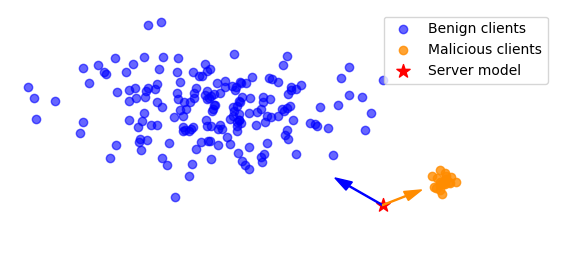

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Set random seed for reproducibility
np.random.seed(44)

# Server model (theta^t)
server = np.array([0, 0])

# Generate benign clients (oval-shaped cluster)
benign_center = np.array([-3, 2])
benign_noise = np.random.randn(180, 2) * [1.2, 0.6]  # Oval shape: wider in x
benign_clients = benign_center + benign_noise

# Generate malicious clients (tight cluster)
malicious_center = np.array([1, 0.5])
malicious_clients = malicious_center + np.random.randn(20, 2) * 0.1

# Compute average direction vectors
benign_direction = np.mean(benign_clients - server, axis=0)
malicious_direction = np.mean(malicious_clients - server, axis=0)

# Normalize for arrow plotting
benign_dir_unit = benign_direction / np.linalg.norm(benign_direction)
malicious_dir_unit = malicious_direction / np.linalg.norm(malicious_direction) * 0.75

# Plotting
plt.figure(figsize=(6, 3))

# Plot benign and malicious clients
plt.scatter(*benign_clients.T, color='blue', alpha=0.6, label='Benign clients')
plt.scatter(*malicious_clients.T, color='darkorange', alpha=0.8, label='Malicious clients')

# Plot server model
plt.scatter(*server, color='red', s=100, marker='*', label=r'Server model')

# Draw direction arrows
plt.arrow(*server, *benign_dir_unit, color='blue', width=0.02, head_width=0.2, length_includes_head=True)
plt.arrow(*server, *malicious_dir_unit, color='darkorange', width=0.02, head_width=0.2, length_includes_head=True)

# Optional: Show direction angle
from numpy.linalg import norm
cos_angle = np.dot(benign_dir_unit, malicious_dir_unit) / (norm(benign_dir_unit) * norm(malicious_dir_unit))
angle_deg = np.degrees(np.arccos(cos_angle))
# plt.title(f'Angle between directions: {angle_deg:.1f}°', fontsize=14)

# Add legend
plt.legend()

# Add white space by setting limits manually
plt.xlim(-6.5, 3.0)
plt.ylim(-1.0, 4.0)

plt.grid(False)
plt.axis('off')  # Removes axis lines, labels, ticks
plt.tight_layout(pad=2)  # Add padding for white space
plt.show()


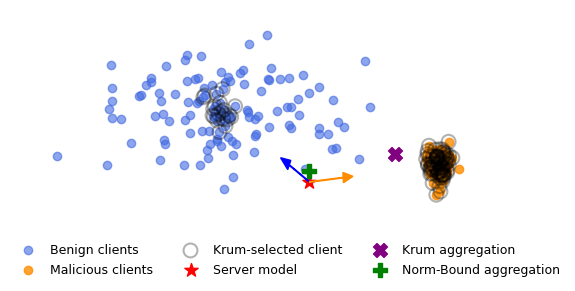

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Reproducibility
np.random.seed(43)
torch.manual_seed(43)

# Server model (theta^t)
server = np.array([0.0, 0.0])
server_tensor = torch.tensor(server, dtype=torch.float32)

# ---- Parameters ----
n_benign = 120
n_malicious = 80
n_total = n_benign + n_malicious

# Multi-Krum settings
f = n_total // 2 - 1
m = n_total // 2 - 1

# ---- Generate client updates ----

# Benign cluster (moved further to the left)
benign_center = np.array([-4, 2])
benign_noise = np.random.randn(n_benign, 2) * [2.5, 1.0]
benign_clients = benign_center + benign_noise

# Malicious cluster (moved further to the right)
malicious_center = np.array([6, 0.5])
malicious_clients = malicious_center + np.random.randn(n_malicious, 2) * 0.3

# Combine all clients
all_clients = np.vstack([benign_clients, malicious_clients])

# ---- Client updates relative to server ----
model_sample_weight_dict = {
    f"client_{i}": torch.tensor(all_clients[i] - server, dtype=torch.float32).reshape(1, -1)
    for i in range(n_total)
}

# ---- Krum implementation ----
def krum(model_sample_weight_dict, f, m):
    n = len(model_sample_weight_dict)
    assert f < (n / 2), "f must be less than n/2"
    assert m <= n - f - 2, "m must be <= n - f - 2 for Multi-Krum to be robust"

    krum_scores = {}
    l2_dist = {k: [] for k in model_sample_weight_dict}

    for k1, v1 in model_sample_weight_dict.items():
        for k2, v2 in model_sample_weight_dict.items():
            if k1 != k2:
                dist = torch.norm(v1 - v2, p=2).item()
                l2_dist[k1].append(dist)

    for name, dists in l2_dist.items():
        sorted_distances = sorted(dists)
        krum_scores[name] = sum(sorted_distances[:n - f - 2])

    sorted_krum_scores = sorted(krum_scores.items(), key=lambda x: x[1])
    selected_clients = [name for name, _ in sorted_krum_scores[:m]]
    return selected_clients

# ---- Run Krum ----
krum_selected = krum(model_sample_weight_dict, f=f, m=m)
krum_selected_indices = [int(name.split('_')[1]) for name in krum_selected]

# ---- Aggregated vectors ----
krum_agg_vector = np.mean(
    [model_sample_weight_dict[name].numpy().flatten() for name in krum_selected],
    axis=0
)
krum_aggregated = server + krum_agg_vector

updates = all_clients - server
normalized_updates = updates / np.linalg.norm(updates, axis=1, keepdims=True)
normbound_aggregated_vector = np.mean(normalized_updates, axis=0)
normbound_aggregated = server + normbound_aggregated_vector

# ---- Direction Arrows ----
benign_direction = np.mean(benign_clients - server, axis=0)
malicious_direction = np.mean(malicious_clients - server, axis=0)
benign_dir_unit = benign_direction / np.linalg.norm(benign_direction) * 1.5
malicious_dir_unit = malicious_direction / np.linalg.norm(malicious_direction) * 2

# ---- Plotting ----
plt.figure(figsize=(6, 3))

plt.scatter(*benign_clients.T, color='royalblue', alpha=0.6, label='Benign clients')
plt.scatter(*malicious_clients.T, color='darkorange', alpha=0.8, label='Malicious clients')

# Transparent circles for Krum-selected clients
for idx in krum_selected_indices:
    plt.scatter(*all_clients[idx], facecolors='none', edgecolors='black', 
                s=100, linewidths=1.5, alpha=0.3,
                label='Krum-selected client' if idx == krum_selected_indices[0] else "")

# Server model
plt.scatter(*server, color='red', s=100, marker='*', label='Server model')

# Direction arrows
plt.arrow(*server, *benign_dir_unit, color='blue', width=0.02, head_width=0.3, length_includes_head=True)
plt.arrow(*server, *malicious_dir_unit, color='darkorange', width=0.02, head_width=0.3, length_includes_head=True)

# Aggregated updates
plt.scatter(*krum_aggregated, color='purple', marker='X', s=100, label='Krum aggregation')
plt.scatter(*normbound_aggregated, color='green', marker='P', s=100, label='Norm-Bound aggregation')

# Final layout
plt.xlim(-12, 10)
plt.ylim(-2, 5)
plt.axis('off')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
# Save as high-quality PNG
plt.savefig("multi_krum_visualization.png", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


In [ ]:
import os
import re
import csv

# === Configuration ===
agr = "rfa"
log_dir = "/home1/liyang/GitHub/FedOda/logs_fl/svhn/Ssvhn_20250628_203307_AGGR_geometric_median_cross-eval/20250629_133732_FedOda_0.3"  # directory containing .log files
output_csv = f"{agr}_actions.csv"

# === Regular Expression to capture action values ===
action_pattern = re.compile(r"action:\s*\[\s*'([-+]?[0-9]*\.?[0-9]+)'\s*,\s*'([-+]?[0-9]*\.?[0-9]+)'\s*\]")

# === Gather data ===
all_data = []

for filename in os.listdir(log_dir):
    if filename.endswith(".log"):
        filepath = os.path.join(log_dir, filename)
        defense_name = agr  # e.g., 'L' from L_20250629_105628.log
        
        with open(filepath, 'r') as file:
            for line in file:
                match = action_pattern.search(line)
                if match:
                    action1 = float(match.group(1))
                    action2 = float(match.group(2))
                    all_data.append([defense_name, action1, action2])

# === Save to CSV ===
with open(output_csv, 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(['defense', 'action1', 'action2'])
    writer.writerows(all_data)

print(f"✅ Extracted {len(all_data)} actions and saved to {output_csv}")


✅ Extracted 185 actions and saved to rfa_actions.csv


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os

# Step 1: Load all *_actions.csv files
files = glob.glob("*_actions.csv")  # or specify path if needed
all_data = []

for file in files:
    df = pd.read_csv(file)
    df['iteration'] = range(len(df))  # Add iteration index
    all_data.append(df)

# Combine all into one DataFrame
data = pd.concat(all_data, ignore_index=True)


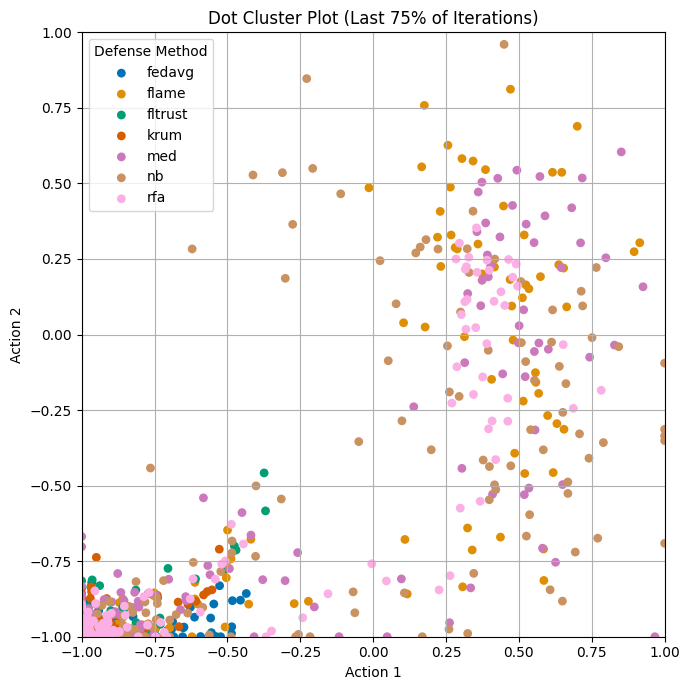

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
from matplotlib.colors import ListedColormap

# === CONFIGURATION ===
filter_fraction = 0.75
alpha_gamma = 1
use_kde = True
show_territory = False

# === Load Data ===
files = glob.glob("*_actions.csv")
data = pd.concat(
    [pd.read_csv(f).assign(iteration=lambda df: range(len(df))) for f in files],
    ignore_index=True
)

# === Filter Last X% ===
filtered = pd.concat([
    g.iloc[int(len(g)*(1-filter_fraction)):].assign(iteration=lambda df: range(len(df)))
    for _, g in data.groupby("defense")
], ignore_index=True)

# === Plot Setup ===
plt.figure(figsize=(7, 7))
plt.title(f"Dot Cluster Plot (Last {int(filter_fraction * 100)}% of Iterations)")
plt.xlabel("Action 1")
plt.ylabel("Action 2")
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.grid(True)

# === Solid, vivid colors (colorblind friendly) ===
import seaborn as sns
defenses = sorted(filtered['defense'].unique())
palette = sns.color_palette("colorblind", len(defenses))
colors = dict(zip(defenses, palette))

# === Plot Each Defense ===
for defense in defenses:
    group = filtered[filtered['defense'] == defense].reset_index(drop=True)
    N = len(group)
    color = colors[defense]
    alpha = 1.0 if alpha_gamma == 0 else np.linspace(0.1, 1.0, N) ** alpha_gamma

    plt.scatter(group['action1'], group['action2'],
                color=[color], alpha=alpha if isinstance(alpha, float) else 1.0,
                label=defense, s=40, edgecolors='none')

# === Legend ===
plt.legend(title='Defense Method', loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


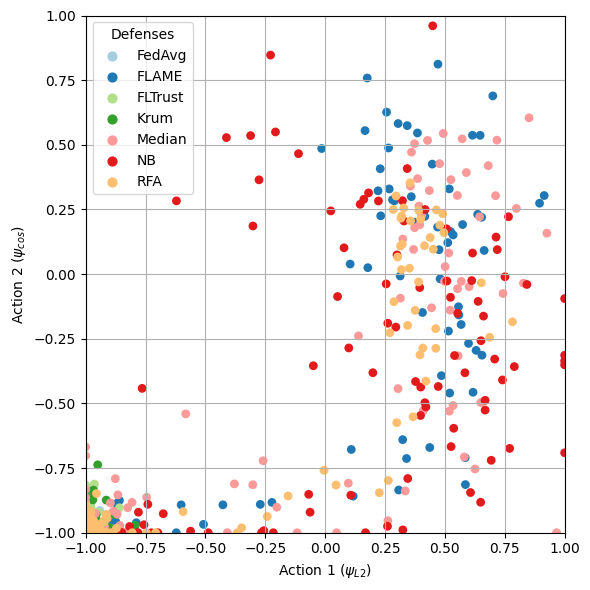

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
import seaborn as sns

# === CONFIGURATION ===
filter_fraction = 0.5      # Use last 66% of iterations
alpha_gamma = 0            # 0 = no fade (solid), >0 = fading effect
palette_name = "Paired"        # Color palette: "Set1", "colorblind", etc.
show_territory = False       # No background KDE shading

# === Custom Legend Names (Optional) ===
custom_legend_names = {
    'fedavg': 'FedAvg',
    'flame': 'FLAME',
    'fltrust': 'FLTrust',
    'krum': 'Krum',
    'med': 'Median',
    'nb': 'NB',
    'rfa': 'RFA'
}

# === Load Data ===
files = glob.glob("*_actions.csv")
data = pd.concat(
    [pd.read_csv(f).assign(iteration=lambda df: range(len(df))) for f in files],
    ignore_index=True
)

# === Filter Last X% ===
filtered = pd.concat([
    g.iloc[int(len(g)*(1 - filter_fraction)):].assign(iteration=lambda df: range(len(df)))
    for _, g in data.groupby("defense")
], ignore_index=True)

# === Setup Plot ===
plt.figure(figsize=(6, 6))
# plt.title(f"Dot Cluster Plot (Last {int(filter_fraction * 100)}% of Iterations)")
plt.xlabel("Action 1 ($\psi_{L2}$)")
plt.ylabel("Action 2 ($\psi_{cos}$)")
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.grid(True)

# === Prepare Colors ===
defenses = sorted(filtered['defense'].unique())
palette = sns.color_palette(palette_name, len(defenses))
colors = dict(zip(defenses, palette))

# === Plot Each Defense ===
for defense in defenses:
    group = filtered[filtered['defense'] == defense].reset_index(drop=True)
    N = len(group)
    color = colors[defense]

    # Calculate per-point alpha
    if alpha_gamma == 0:
        alphas = np.ones(N)
    else:
        alphas = np.linspace(0.1, 1.0, N) ** alpha_gamma

    # Plot each point with its own alpha
    for i in range(N):
        plt.scatter(group['action1'].iloc[i], group['action2'].iloc[i],
                    color=color, alpha=alphas[i], s=40, edgecolors='none')

# === Custom Legend ===
# Plot one dummy point per legend entry
for defense in defenses:
    plt.scatter([], [], color=colors[defense], label=custom_legend_names.get(defense, defense), s=40)

plt.legend(title='Defenses', loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


In [16]:
import os
import re
import csv

# === Configuration ===
agr = "ResNet14"  # Aggregation rule or defense name
log_dir = "/ntuzfs/liyang/GitHub/FedOda/logs_fl/cifar10/Scifar10_20250702_172212_AGGR_geometric_median_cross-eval/20250702_200118_FedOda_0.5"
output_csv = f"{agr}_cos_dist.csv"

# === Updated Regular Expression to capture cosine distance ===
cos_dist_pattern = re.compile(r"Cosine distance between g_m and g_b:\s*([0-9]*\.?[0-9]+)")

# === Gather data ===
all_data = []

for filename in os.listdir(log_dir):
    if filename.endswith(".log"):
        filepath = os.path.join(log_dir, filename)
        defense_name = agr  # Or extract from filename if needed

        with open(filepath, 'r') as file:
            for line in file:
                match = cos_dist_pattern.search(line)
                if match:
                    cos_dist = float(match.group(1))
                    all_data.append([defense_name, cos_dist])

# === Save to CSV ===
with open(output_csv, 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(['defense', 'cos_dist'])
    writer.writerows(all_data)

print(f"✅ Extracted {len(all_data)} cosine distances and saved to {output_csv}")


✅ Extracted 299 cosine distances and saved to ResNet14_cos_dist.csv


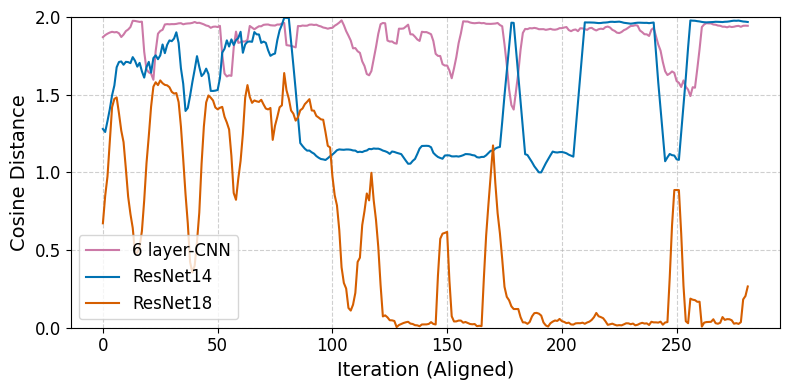

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load CSVs
resnet14_df = pd.read_csv("ResNet14_cos_dist.csv")
resnet18_df = pd.read_csv("ResNet18_cos_dist.csv")
convnet_df  = pd.read_csv("SimpleCNN_32_cos_dist.csv")

# Find the shortest length
min_len = min(len(resnet14_df), len(resnet18_df), len(convnet_df))

def downsample(df, target_len):
    indices = np.linspace(0, len(df) - 1, target_len).astype(int)
    return df.iloc[indices].reset_index(drop=True)

# Downsample
resnet14 = downsample(resnet14_df, min_len)
resnet18 = downsample(resnet18_df, min_len)
convnet  = downsample(convnet_df,  min_len)

# === Moving average smoothing ===
def smooth(series, window=5):
    return series.rolling(window=window, center=True, min_periods=1).mean()

resnet14_smooth = smooth(resnet14['cos_dist'])
resnet18_smooth = smooth(resnet18['cos_dist'])
convnet_smooth  = smooth(convnet['cos_dist'])

# Colors
colors = {
    'ResNet18': '#D55E00',  # Vermillion (strong, professional orange-red)
    'ResNet14': '#0072B2',  # Oxford Blue (clean and academic)
    'ConvNet':  '#CC79A7',  # Reddish Purple (distinct but subtle)
}
# Plot
plt.figure(figsize=(8, 4))

plt.plot(convnet_smooth,  label='6 layer-CNN',  color=colors['ConvNet'],  linewidth=1.5)
plt.plot(resnet14_smooth, label='ResNet14', color=colors['ResNet14'], linewidth=1.5)
plt.plot(resnet18_smooth, label='ResNet18', color=colors['ResNet18'], linewidth=1.5)

# Set fixed y-axis tick range: up to 2, step = 0.5
plt.yticks(np.arange(0, 2.1, 0.5), fontsize=12)  # from 0 to 2 inclusive

# Optional: force y-axis limits if needed
plt.ylim(0, 2)

# Axis labels and grid
plt.xlabel("Iteration (Aligned)", fontsize=14)
plt.ylabel("Cosine Distance", fontsize=14)
plt.xticks(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Legend and layout
plt.legend(fontsize=12, loc='best')
plt.tight_layout()

# Save as high-quality image
plt.savefig("cos_b_m.png", dpi=300, bbox_inches='tight')

# Show plot
plt.show()
